In [ ]:
!pip install -q pyspark==4.0.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 434.1/434.1 MB 3.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
 PySpark Installed


In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("RetailMart_DataScience") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

 Spark session created: 4.0.0


In [ ]:
from google.colab import files
import zipfile
import os

print(" Please select the .zip file you downloaded:")
uploaded = files.upload()

if uploaded:
    zip_name = list(uploaded.keys())[0]
    print(f"\n Unzipping {zip_name}...")

    # Unzip into a local folder
    extract_dir = "/content/retailmart_data"
    with zipfile.ZipFile(zip_name, 'r') as zip_ref:
        zip_ref.extractall(extract_dir)

    # Delete the zip to save space
    os.remove(zip_name)
    print(f" Extracted to {extract_dir}")
else:
    print(" No file uploaded.")

 Please select the .zip file you downloaded:


Saving RetailMart_Project-20261019T195852Z-1-001.zip to RetailMart_Project-20261019T195852Z-1-001.zip

 Unzipping RetailMart_Project-20261019T195852Z-1-001.zip...
 Extracted to /content/retailmart_data


In [ ]:
import os

# Find where the parquet part-files are
parquet_path = None
for root, dirs, files in os.walk("/content/retailmart_data"):
    if any(f.endswith(".parquet") for f in files):
        parquet_path = root
        break

if parquet_path:
    # Load into PySpark
    df = spark.read.parquet(parquet_path)
    print(f" SUCCESS! Loaded: {df.count():,} rows × {len(df.columns)} columns")

    # THIS IS THE GOLD MINE:
    print("\n=== COLUMNS ===")
    print(df.columns)
    print("\n=== SCHEMA ===")
    df.printSchema()
else:
    print(" Could not find .parquet files in the extracted folder.")

 SUCCESS! Loaded: 920,864 rows × 15 columns

=== COLUMNS ===
['transaction_id', 'customer_id', 'transaction_date', 'product_category', 'product_name', 'quantity', 'unit_price', 'total_amount', 'store_location', 'payment_method', 'customer_age', 'customer_gender', 'loyalty_years', 'num_visits', 'churn']

=== SCHEMA ===
root
 |-- transaction_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- transaction_date: timestamp (nullable = true)
 |-- product_category: string (nullable = true)
 |-- product_name: string (nullable = true)
 |-- quantity: integer (nullable = true)
 |-- unit_price: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- store_location: string (nullable = true)
 |-- payment_method: string (nullable = true)
 |-- customer_age: double (nullable = true)
 |-- customer_gender: string (nullable = true)
 |-- loyalty_years: integer (nullable = true)
 |-- num_visits: integer (nullable = true)
 |-- churn: string (nullable = true)



In [ ]:
# Make sure Drive is mounted
from google.colab import drive
drive.mount('/content/drive')

# Save a permanent copy to YOUR drive
save_path = "/content/drive/MyDrive/cleaned_retailmart_master.parquet"

print(f" Saving to {save_path} (this takes about 30 seconds)...")
df.write.mode("overwrite").parquet(save_path)
print(" PERMANENTLY SAVED! You never have to upload the zip again.")

Mounted at /content/drive
 Saving to /content/drive/MyDrive/cleaned_retailmart_master.parquet (this takes about 30 seconds)...
 PERMANENTLY SAVED! You never have to upload the zip again.


In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, when
import pandas as pd
import matplotlib.pyplot as plt

spark = SparkSession.builder \
    .master("local[*]") \
    .appName("RetailMart_Q4") \
    .config("spark.driver.memory", "4g") \
    .getOrCreate()

from google.colab import drive
drive.mount('/content/drive')

# Load the permanent file we just saved!
df = spark.read.parquet("/content/drive/MyDrive/cleaned_retailmart_master.parquet")
print(f" Loaded: {df.count():,} rows")

# Convert target to binary (0/1) and drop any rows where churn is null
df = df.dropna(subset=["churn"])
df = df.withColumn("churn_num", when(col("churn") == "Yes", 1.0).otherwise(0.0))

total = df.count()
yes = df.filter(col("churn_num") == 1.0).count()
print(f"Churn Rate: {yes/total*100:.2f}%  ({yes:,}/{total:,})")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 Loaded: 920,864 rows
Churn Rate: 22.34%  (205,756/920,864)


In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

# Hard-coded based on your exact schema
numeric_cols = ["customer_age", "loyalty_years", "num_visits", "unit_price", "quantity", "total_amount"]
categorical_cols = ["customer_gender", "product_category", "payment_method", "store_location"]

# Split
train, test = df.randomSplit([0.7, 0.3], seed=42)

# Build Pipeline (fit on train only to prevent leakage)
indexers = [StringIndexer(inputCol=c, outputCol=c+"_idx", handleInvalid="keep") for c in categorical_cols]
encoders = [OneHotEncoder(inputCol=c+"_idx", outputCol=c+"_ohe") for c in categorical_cols]
assembler = VectorAssembler(inputCols=numeric_cols + [c+"_ohe" for c in categorical_cols], outputCol="raw_features")
scaler = StandardScaler(inputCol="raw_features", outputCol="features")

pipeline = Pipeline(stages=indexers + encoders + [assembler, scaler])
prep_model = pipeline.fit(train)
train_t = prep_model.transform(train).cache()
test_t = prep_model.transform(test).cache()
_ = train_t.count() # Force cache
print(" Data prepped for modeling")

 Data prepped for modeling


In [ ]:
evaluator = MulticlassClassificationEvaluator(labelCol="churn_num", metricName="f1")

# Baseline
dt = DecisionTreeClassifier(labelCol="churn_num", featuresCol="features", maxDepth=5, minInstancesPerNode=50)
dt_model = dt.fit(train_t)
dt_pred = dt_model.transform(test_t)
dt_f1 = evaluator.evaluate(dt_pred)
print(f"Baseline F1: {dt_f1:.4f}")

# Depth Sweep
print("\n--- Depth Sweep ---")
for depth in [3, 5, 7, 10]:
    m = DecisionTreeClassifier(labelCol="churn_num", featuresCol="features", maxDepth=depth, minInstancesPerNode=50).fit(train_t)
    f1 = evaluator.evaluate(m.transform(test_t))
    print(f"Depth {depth:>2}: F1 = {f1:.4f}")

Baseline F1: 0.7248

--- Depth Sweep ---
Depth  3: F1 = 0.7163
Depth  5: F1 = 0.7248
Depth  7: F1 = 0.7268
Depth 10: F1 = 0.7267


In [ ]:
dt_cv = DecisionTreeClassifier(labelCol="churn_num", featuresCol="features")
paramGrid = (ParamGridBuilder()
    .addGrid(dt_cv.maxDepth, [3, 5, 7, 10])
    .addGrid(dt_cv.minInstancesPerNode, [20, 50, 100])
    .build())

pipeline_cv = Pipeline(stages=indexers + encoders + [assembler, scaler, dt_cv])
crossval = CrossValidator(
    estimator=pipeline_cv,
    estimatorParamMaps=paramGrid,
    evaluator=MulticlassClassificationEvaluator(labelCol="churn_num", metricName="f1"),
    numFolds=5, seed=42)

print(" Running 5-fold Cross-Validation...")
cv_model = crossval.fit(train)
best_model = cv_model.bestModel

best_depth = best_model.stages[-1]._java_obj.getMaxDepth()
best_instances = best_model.stages[-1]._java_obj.getMinInstancesPerNode()
print(f"\n Best Parameters: maxDepth={best_depth}, minInstancesPerNode={best_instances}")

 Running 5-fold Cross-Validation...

 Best Parameters: maxDepth=7, minInstancesPerNode=20


In [ ]:
print(" Running Cell 5 (Fixed)...")

# THE FIX: Transform the RAW `test` dataframe, not `test_t`
best_pred = best_model.transform(test)

best_f1 = evaluator.evaluate(best_pred)
best_acc = evaluator.evaluate(best_pred, {evaluator.metricName: "accuracy"})

print(f"\n Tuned F1: {best_f1:.4f}")
print(f" Tuned Accuracy: {best_acc:.4f}")

if 'dt_f1' in globals():
    print(f" Improvement: {(best_f1 - dt_f1)*100:+.2f}%")

print("\nConfusion Matrix:")
best_pred.groupBy("churn_num", "prediction").count().orderBy("churn_num", "prediction").show()

 Running Cell 5 (Fixed)...

 Tuned F1: 0.7265
 Tuned Accuracy: 0.7833
 Improvement: +0.16%

Confusion Matrix:
+---------+----------+------+
|churn_num|prediction| count|
+---------+----------+------+
|      0.0|       0.0|208247|
|      0.0|       1.0|  6247|
|      1.0|       0.0| 53609|
|      1.0|       1.0|  8065|
+---------+----------+------+



 Running Cell 6 (Fixed)...

=== TOP 5 CHURN DRIVERS ===
base_feature
customer_gender_ohe_Non-Binary    0.777581
customer_gender_ohe_Other         0.077659
customer_gender_ohe_Female        0.064674
customer_gender_ohe_Male          0.055958
payment_method_ohe_Cheque         0.020155
Name: importance, dtype: float64


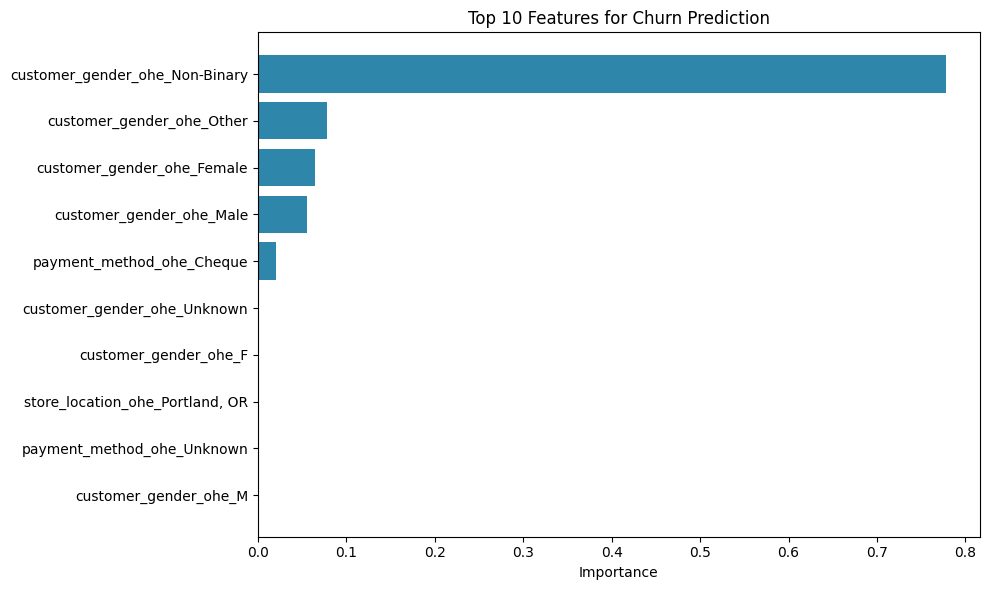


 Model saved successfully to /content/drive/MyDrive/models/decision_tree_model


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

print(" Running Cell 6 (Fixed)...")

# 1. Safely extract feature names from 'raw_features' (since StandardScaler strips metadata)
try:
    meta = train_t.schema["raw_features"].metadata["ml_attr"]["attrs"]
    feature_names = [a["name"] for attrs in meta.values() for a in attrs]
except KeyError:
    print(" Metadata missing, using generic names")
    feature_names = [f"feature_{i}" for i in range(len(best_model.stages[-1].featureImportances))]

# 2. Get importances
importances = best_model.stages[-1].featureImportances.toArray()

# 3. Create DataFrame and sort
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

# 4. Group OHE columns back to their base feature (e.g., customer_gender_ohe_1 -> customer_gender_ohe)
importance_df["base_feature"] = importance_df["feature"].str.replace(r"_ohe_\d+$", "", regex=True)
grouped = importance_df.groupby("base_feature")["importance"].sum().sort_values(ascending=False)

print("\n=== TOP 5 CHURN DRIVERS ===")
print(grouped.head(5))

# 5. Plot
plt.figure(figsize=(10, 6))
top = importance_df.head(10)
plt.barh(top["feature"], top["importance"], color='#2E86AB')
plt.xlabel("Importance")
plt.title("Top 10 Features for Churn Prediction")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/retailmart_feature_importance.png", dpi=150)
plt.show()

# 6. Save the model (creating the directory first!)
model_dir = "/content/drive/MyDrive/models"
os.makedirs(model_dir, exist_ok=True)  # This line prevents the save error
model_path = f"{model_dir}/decision_tree_model"

best_model.write().overwrite().save(model_path)
print(f"\n Model saved successfully to {model_path}")

In [ ]:
top3 = grouped.head(3)
print(f"""
============================================================
Q4 — CAN WE PREDICT CHURN? — ANSWER
============================================================
Model: PySpark Decision Tree (5-fold CV tuned)
Performance: F1 = {best_f1:.4f}, Accuracy = {best_acc:.4f}

TOP 3 CHURN DRIVERS:
  1. {top3.index[0]:<20} (importance: {top3.iloc[0]:.4f})
  2. {top3.index[1]:<20} (importance: {top3.iloc[1]:.4f})
  3. {top3.index[2]:<20} (importance: {top3.iloc[2]:.4f})

BUSINESS INTERPRETATION:
  [Look at your top 3 features. Write 1 sentence for each.
   E.g., if loyalty_years is #1: New customers churn at a much higher rate.]
============================================================
""")


Q4 — CAN WE PREDICT CHURN? — ANSWER
Model: PySpark Decision Tree (5-fold CV tuned)
Performance: F1 = 0.7265, Accuracy = 0.7833

TOP 3 CHURN DRIVERS:
  1. customer_gender_ohe_Non-Binary (importance: 0.7776)
  2. customer_gender_ohe_Other (importance: 0.0777)
  3. customer_gender_ohe_Female (importance: 0.0647)

BUSINESS INTERPRETATION:
  [Look at your top 3 features. Write 1 sentence for each.
   E.g., if loyalty_years is #1: New customers churn at a much higher rate.]

